# Phase 2 — Exploratory Data Analysis: GDELT × Brent Crude Oil

**Research question:** How does geopolitical event activity and sentiment relate to Brent crude oil price movements?

**Six approved investigations:** (1) global activity vs Brent trends; (2) CAMEO event composition; (3) negative news vs returns; (4) Iran/Russia Goldstein vs Brent; (5) exporter vs importer signals; (7) internal exporter activity vs Brent.

**Method:** exploratory / descriptive, not causal or predictive proof. Interpret plots together with numerical summaries, consider outliers and limited sample size. Price returns exist only on published Brent observation dates. GDELT events remain available for every calendar day.

**Presentation:** Select 3–5 findings based on actual results. Each section ends with questions to help prepare the 7-minute EDA discussion. No input files are edited.

## 0. Setup and dataset quality

Load the previously validated **164 × 86** merged file. Change `PROJECT_DIR` only if the notebook is launched from an unusual working directory. All figures and tables are saved under `outputs/eda_brent_selected/`.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy import stats
from IPython.display import display

# Matplotlib defaults; plots are suitable for presentation export.
plt.rcParams.update({"figure.figsize": (11, 5.5), "figure.dpi": 115, "axes.grid": True, "grid.alpha": 0.22, "font.size": 10})

cwd = Path.cwd().resolve()
possible_roots = [cwd, cwd.parent, cwd.parent.parent]
PROJECT_DIR = next((p for p in possible_roots if (p / "data" / "processed" / "gdelt_brent_daily.parquet").exists()), None)
if PROJECT_DIR is None:
    raise FileNotFoundError("gdelt_brent_daily.parquet not found. Place notebook under Data_wizards/notebook/, and run there.")
DATA_FILE = PROJECT_DIR / "data" / "processed" / "gdelt_brent_daily.parquet"
OUT_DIR = PROJECT_DIR / "outputs" / "eda_brent_selected"
OUT_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_parquet(DATA_FILE).copy()
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").reset_index(drop=True)
assert df["date"].is_unique and df["date"].notna().all()
required = ["global_total_events", "brent_price", "brent_return", "global_goldstein_mean", "global_tone_mean", "global_negative_tone_share", "iran_goldstein_mean", "russia_goldstein_mean", "exporter_total_events", "importer_total_events", "exporter_goldstein_mean", "importer_goldstein_mean", "exporter_internal_event_share", "importer_internal_event_share"] + [f"global_root_{i:02d}" for i in range(1, 21)]
missing = [c for c in required if c not in df]
assert not missing, f"Missing required columns: {missing}"
assert (df["brent_price"].dropna() > 0).all()
price_days = df[df["brent_price"].notna()].copy()
print("Source:", DATA_FILE)
print("Dimensions:", df.shape, "| Period:", df.date.min().date(), "to", df.date.max().date())
print("Price days:", len(price_days), "| Unobserved prices:", df.brent_price.isna().sum(), "| Valid returns:", df.brent_return.notna().sum())
print("Global GDELT records:", f"{int(df.global_total_events.sum()):,}")
print("Output folder:", OUT_DIR)
display(df[["date", "global_total_events", "brent_price", "brent_return"]].head(8))

def savefig(name):
    plt.tight_layout()
    plt.savefig(OUT_DIR / f"{name}.png", dpi=180, bbox_inches="tight")
    plt.show()

def corr_summary(feature, target="brent_return", data=None, method="pearson"):
    d = df if data is None else data
    p = d[[feature, target]].replace([np.inf, -np.inf], np.nan).dropna()
    if len(p) < 4 or p[feature].nunique() < 2 or p[target].nunique() < 2:
        return {"feature": feature, "target": target, "n": len(p), "r": np.nan, "p_value": np.nan}
    f = stats.pearsonr if method == "pearson" else stats.spearmanr
    r, pv = f(p[feature], p[target])
    return {"feature": feature, "target": target, "n": len(p), "r": r, "p_value": pv}

def scatter_compare(ax, x, y, xlabel, ylabel, title):
    temp = pd.DataFrame({"x": x, "y": y}).replace([np.inf, -np.inf], np.nan).dropna()
    ax.scatter(temp["x"], temp["y"], s=27, alpha=.65)
    if len(temp) >= 4 and temp.x.nunique() > 1:
        slope, intercept = np.polyfit(temp.x, temp.y, 1)
        grid = np.linspace(temp.x.min(), temp.x.max(), 100)
        ax.plot(grid, slope*grid+intercept, linewidth=2)
        r, pv = stats.pearsonr(temp.x, temp.y)
        ax.set_title(f"{title}\nPearson r={r:.3f}, n={len(temp)}")
    else: ax.set_title(title)
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)

Source: C:\Users\kevin\school\Fall 2026\Data Intensive Computing\DIC Semeters Project\Phase 2\Data_wizards\data\processed\gdelt_brent_daily.parquet
Dimensions: (164, 86) | Period: 2025-01-01 to 2025-06-13
Price days: 113 | Unobserved prices: 51 | Valid returns: 112
Global GDELT records: 20,343,168
Output folder: C:\Users\kevin\school\Fall 2026\Data Intensive Computing\DIC Semeters Project\Phase 2\Data_wizards\outputs\eda_brent_selected


,date,global_total_events,brent_price,brent_return
0,2025-01-01,71207.0,NaN,NaN
1,2025-01-02,91632.0,76.14,NaN
2,2025-01-03,106495.0,76.72,0.007618
3,2025-01-04,74608.0,NaN,NaN
4,2025-01-05,64742.0,NaN,NaN
5,2025-01-06,110445.0,77.27,0.007169
6,2025-01-07,129240.0,77.84,0.007377
7,2025-01-08,136893.0,77.37,-0.006038


## 1. Do geopolitical events and Brent prices move together?

**Question:** Does the number of reported worldwide GDELT events rise or fall around changes in Brent prices?  
**Approach:** stacked aligned time-series, not misleading dual-axis superposition. Since both series may trend, we separately examine returns and standardized event counts. **Co-movement is not predictive evidence.**

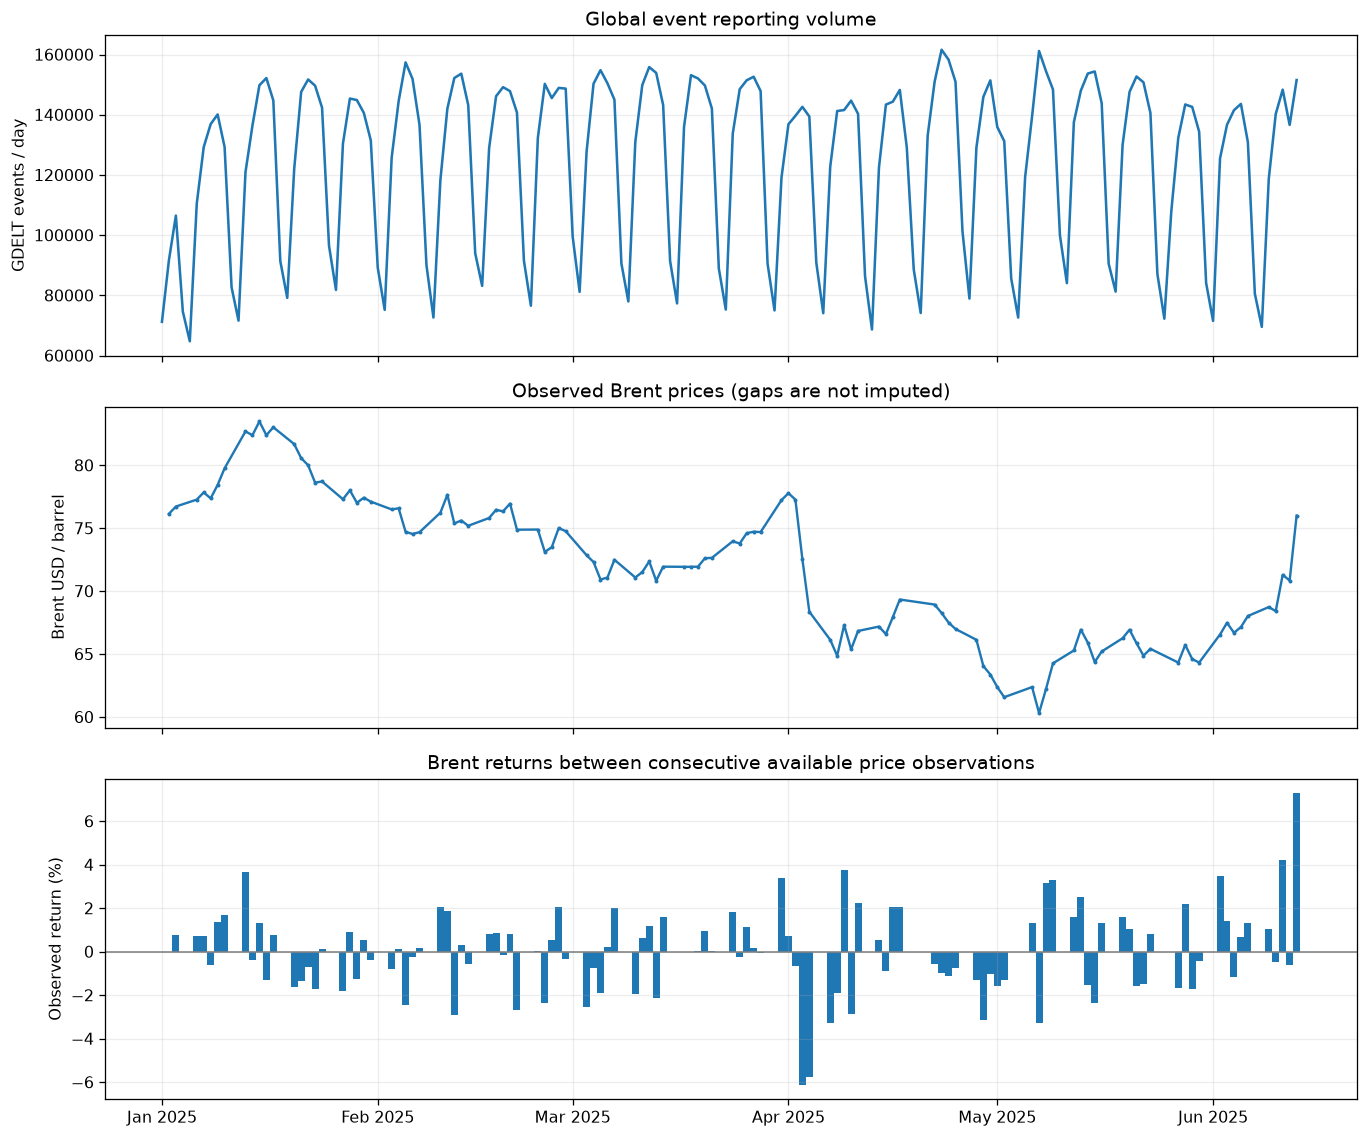

Correlation (same calendar-day matching; not causal):


,feature,target,n,r,p_value
0,global_total_events,brent_price,113,-0.1573,0.0962
1,global_total_events,brent_return,112,-0.1322,0.1647


Event count range: 64,742–161,604
Brent observed price range: $60.31–$83.48


In [2]:
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
axes[0].plot(df.date, df.global_total_events, linewidth=1.6)
axes[0].set_ylabel("GDELT events / day"); axes[0].set_title("Global event reporting volume")
axes[1].plot(price_days.date, price_days.brent_price, marker=".", markersize=3, linewidth=1.5)
axes[1].set_ylabel("Brent USD / barrel"); axes[1].set_title("Observed Brent prices (gaps are not imputed)")
ret = df.dropna(subset=["brent_return"])
axes[2].axhline(0, color="gray", linewidth=1)
axes[2].bar(ret.date, ret.brent_return * 100, width=1.0)
axes[2].set_ylabel("Observed return (%)"); axes[2].set_title("Brent returns between consecutive available price observations")
axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
savefig("01_global_events_brent_timeseries")
summary1 = pd.DataFrame([
    corr_summary("global_total_events", "brent_price"),
    corr_summary("global_total_events", "brent_return")
])
print("Correlation (same calendar-day matching; not causal):")
display(summary1.round(4))
print("Event count range:", f"{df.global_total_events.min():,.0f}–{df.global_total_events.max():,.0f}")
print("Brent observed price range:", f"${price_days.brent_price.min():.2f}–${price_days.brent_price.max():.2f}")
summary1.to_csv(OUT_DIR / "01_global_correlations.csv", index=False)

**Interpretation prompts:** Do visible peaks coincide? Are associations different for **price levels vs returns**? Does day-of-week reporting create regular activity fluctuations? Avoid inferring that event volume causes an oil-price change.

## 2. Which CAMEO geopolitical event categories dominate?

**Question:** What is the event mix behind our indicators—consultation, cooperation, protests, material conflict, etc.?  
**Approach:** count all 20 CAMEO roots, show shares and rank; group low-frequency codes to avoid clutter.

Counts may include repetitive reporting events. CAMEO root category `20` represents *unconventional mass violence*; `19` is *fight*.

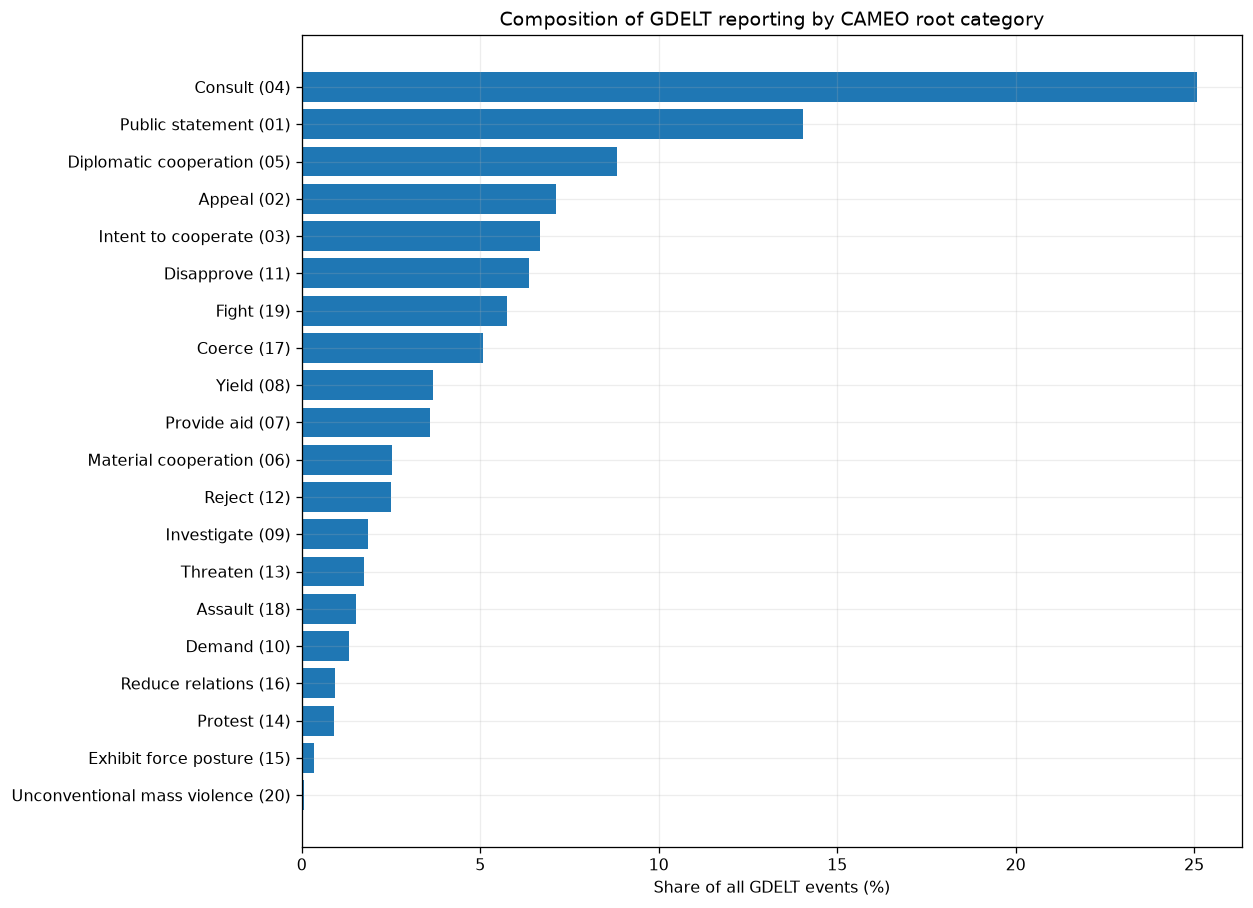

Total root-coded events: 20,343,152
Share coded: 100.00%


,code,events,label,share_of_all_events_pct
0,04,5103696.0,Consult,25.09
1,01,2856569.0,Public statement,14.04
2,05,1799597.0,Diplomatic cooperation,8.85
3,02,1450320.0,Appeal,7.13
4,03,1359217.0,Intent to cooperate,6.68
5,11,1294549.0,Disapprove,6.36
6,19,1171487.0,Fight,5.76
7,17,1031142.0,Coerce,5.07
8,08,746460.0,Yield,3.67
9,07,729467.0,Provide aid,3.59


In [3]:
CAMEO_LABELS = {
 "01":"Public statement", "02":"Appeal", "03":"Intent to cooperate", "04":"Consult", "05":"Diplomatic cooperation",
 "06":"Material cooperation", "07":"Provide aid", "08":"Yield", "09":"Investigate", "10":"Demand",
 "11":"Disapprove", "12":"Reject", "13":"Threaten", "14":"Protest", "15":"Exhibit force posture",
 "16":"Reduce relations", "17":"Coerce", "18":"Assault", "19":"Fight", "20":"Unconventional mass violence"
}
root_counts = pd.Series({code: df[f"global_root_{code}"].sum() for code in CAMEO_LABELS}).sort_values(ascending=False)
root_table = pd.DataFrame({"code": root_counts.index, "events": root_counts.values})
root_table["label"] = root_table["code"].map(CAMEO_LABELS)
root_table["share_of_all_events_pct"] = 100 * root_table.events / df.global_total_events.sum()
fig, ax = plt.subplots(figsize=(11, 8))
order = root_table.iloc[::-1]
ax.barh(order.label + " (" + order.code + ")", order.share_of_all_events_pct)
ax.set_xlabel("Share of all GDELT events (%)")
ax.set_title("Composition of GDELT reporting by CAMEO root category")
savefig("02_cameo_all20_shares")
print("Total root-coded events:", f"{int(root_counts.sum()):,}")
print("Share coded:", f"{100*root_counts.sum()/df.global_total_events.sum():.2f}%")
display(root_table.head(12).round(2))
root_table.to_csv(OUT_DIR / "02_cameo_composition.csv", index=False)

**Interpretation prompts:** Which 3–5 categories account for most reporting? Is conflict dominant, or do statements/consultations outnumber it? Does a high count measure geopolitical importance or simply reporting frequency?

## 3. Does negative geopolitical news correspond to falling Brent prices?

**Question:** Are more negative `AvgTone` values, higher negative-tone shares, or less cooperative Goldstein scores associated with positive/negative Brent returns?  
**Approach:** scatterplots and Pearson/Spearman correlation. Note the direction of the hypothesis: negative developments may **raise** oil prices because of supply risks, not necessarily lower them. Same-day data provide association only.

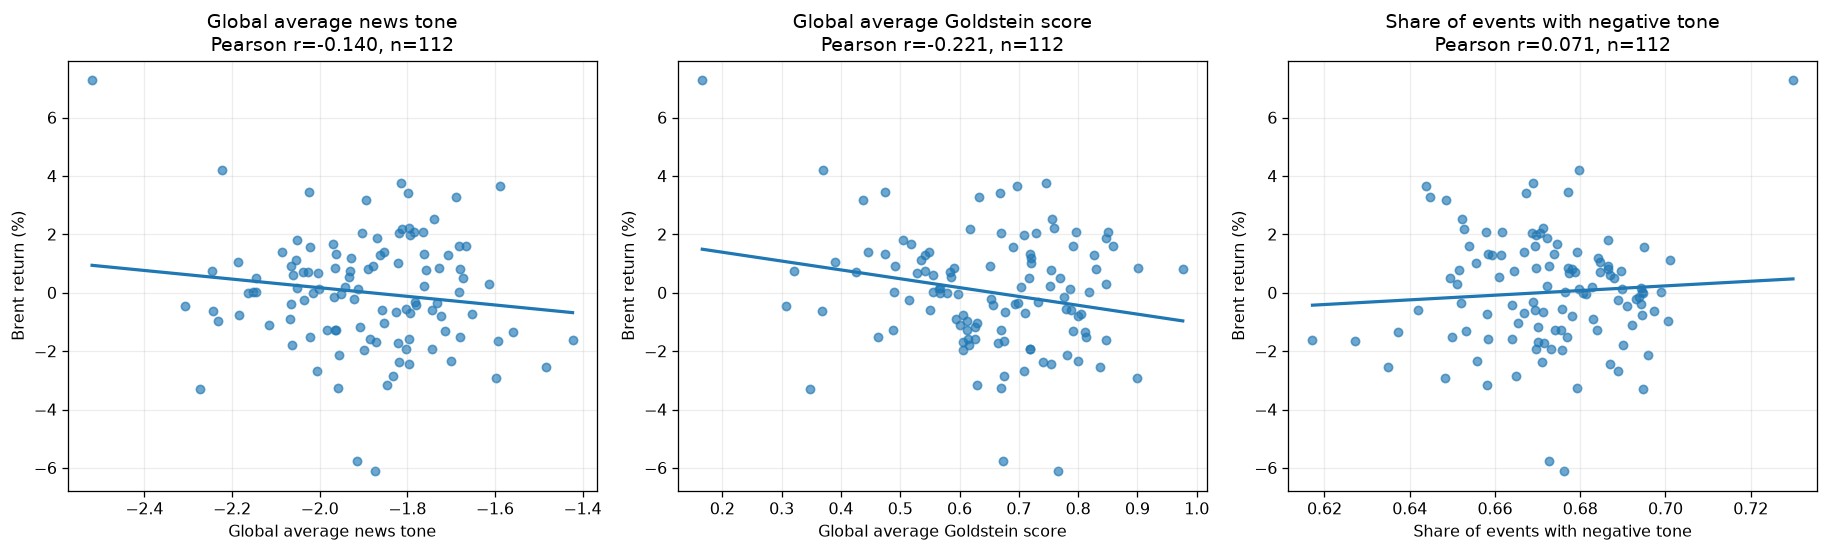

,metric,method,n,r,p_value
0,Global average news tone,pearson,112,-0.1400,0.1410
1,Global average news tone,spearman,112,-0.0411,0.6668
2,Global average Goldstein score,pearson,112,-0.2213,0.0190
3,Global average Goldstein score,spearman,112,-0.1191,0.2110
4,Share of events with negative tone,pearson,112,0.0708,0.4581
5,Share of events with negative tone,spearman,112,-0.0452,0.6358


In [4]:
metrics = [
    ("global_tone_mean", "Global average news tone"),
    ("global_goldstein_mean", "Global average Goldstein score"),
    ("global_negative_tone_share", "Share of events with negative tone"),
]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.9))
for ax, (feature, label) in zip(axes, metrics):
    scatter_compare(ax, df[feature], df.brent_return * 100,
                    label, "Brent return (%)", label)
savefig("03_global_sentiment_vs_brent_return")
rows=[]
for feature, label in metrics:
    for method in ["pearson", "spearman"]:
        rows.append({"metric": label, "method": method, **corr_summary(feature, method=method)})
summary3 = pd.DataFrame(rows)
display(summary3[["metric", "method", "n", "r", "p_value"]].round(4))
summary3.to_csv(OUT_DIR / "03_sentiment_correlations.csv", index=False)

**Interpretation prompts:** Is the direction what you expected? Do Pearson and Spearman disagree (outlier/nonlinear influence)? Does an apparent trend depend on just one or two extreme price moves? **Do not call same-day correlations forecasts.**

## 4. Does geopolitical activity involving Iran and Russia relate to Brent price movements?

**Question:** Are country-related Goldstein scores associated with Brent returns, and do the two countries differ?  
**Approach:** aligned time series and scatterplots. Country scores reflect **events involving the country in either actor field**, not exclusively internal events, domestic unrest, or instability. A negative score generally indicates less cooperative event types; it is not a direct instability scale.

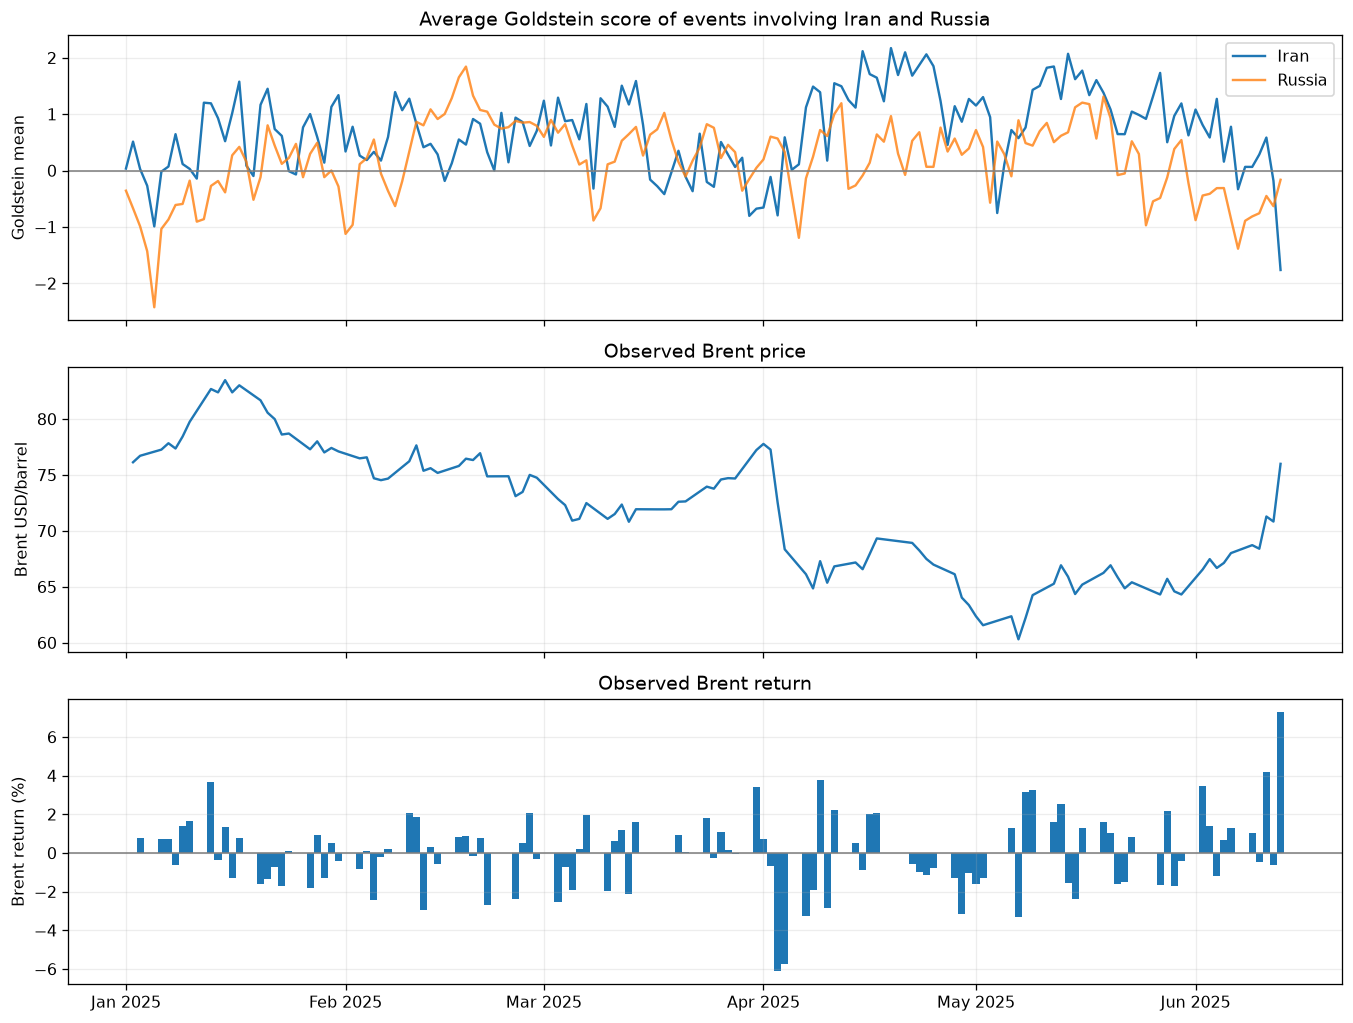

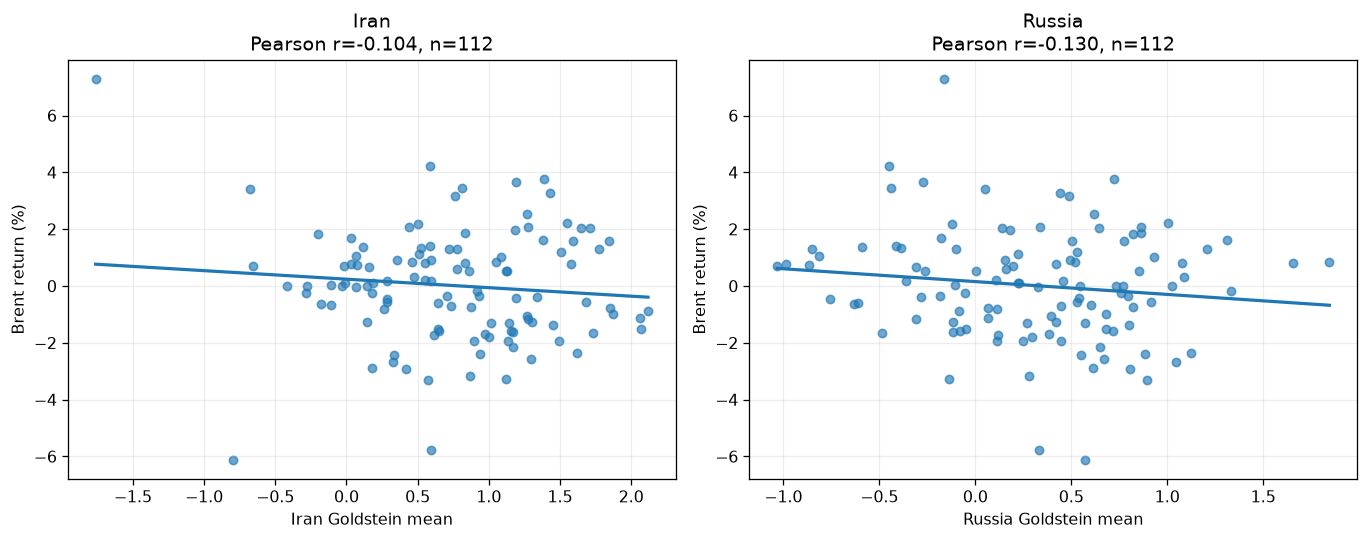

,method,feature,target,n,r,p_value
0,pearson,iran_goldstein_mean,brent_return,112,-0.1041,0.2745
1,spearman,iran_goldstein_mean,brent_return,112,-0.0646,0.4985
2,pearson,russia_goldstein_mean,brent_return,112,-0.1302,0.1712
3,spearman,russia_goldstein_mean,brent_return,112,-0.1056,0.2679


In [5]:
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
axes[0].plot(df.date, df.iran_goldstein_mean, label="Iran")
axes[0].plot(df.date, df.russia_goldstein_mean, label="Russia", alpha=.8)
axes[0].axhline(0, linewidth=1, color="gray")
axes[0].set_title("Average Goldstein score of events involving Iran and Russia")
axes[0].set_ylabel("Goldstein mean"); axes[0].legend()
axes[1].plot(price_days.date, price_days.brent_price)
axes[1].set_ylabel("Brent USD/barrel"); axes[1].set_title("Observed Brent price")
axes[2].bar(ret.date, ret.brent_return*100, width=1)
axes[2].axhline(0, color="gray", linewidth=1)
axes[2].set_ylabel("Brent return (%)"); axes[2].set_title("Observed Brent return")
axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
savefig("04_iran_russia_goldstein_timeseries")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, country in zip(axes, ["iran", "russia"]):
    col = f"{country}_goldstein_mean"
    scatter_compare(ax, df[col], df.brent_return*100, f"{country.title()} Goldstein mean", "Brent return (%)", country.title())
savefig("04_iran_russia_scatter")
rows=[]
for col in ["iran_goldstein_mean", "russia_goldstein_mean"]:
    for method in ["pearson", "spearman"]:
        rows.append({"method": method, **corr_summary(col, method=method)})
summary4 = pd.DataFrame(rows)
display(summary4.round(4)); summary4.to_csv(OUT_DIR / "04_iran_russia_correlations.csv", index=False)

**Interpretation prompts:** Which country, if either, shows a clearer pattern? Do sign and magnitude seem sensitive to outliers? Why can an oil-supply concern create a **positive Brent return** when Goldstein scores are negative?

## 5. Do exporter-related events differ from importer-related events in relation to Brent?

**Question:** Are exporter versus importer event volume and geopolitical sentiment differently associated with Brent returns?  
**Approach:** first compare normalized **daily event shares** (`group_total_events / global_total_events`) to reduce the effect of overall reporting volume. Then compare exporter/importer Goldstein means. This is an EDA rescaling, **not a transformation of the saved raw features**.

**Caution:** broad exporter and importer groups overlap when an event involves both; the shares need not add to 1. Country group definitions come from the historical research specification.

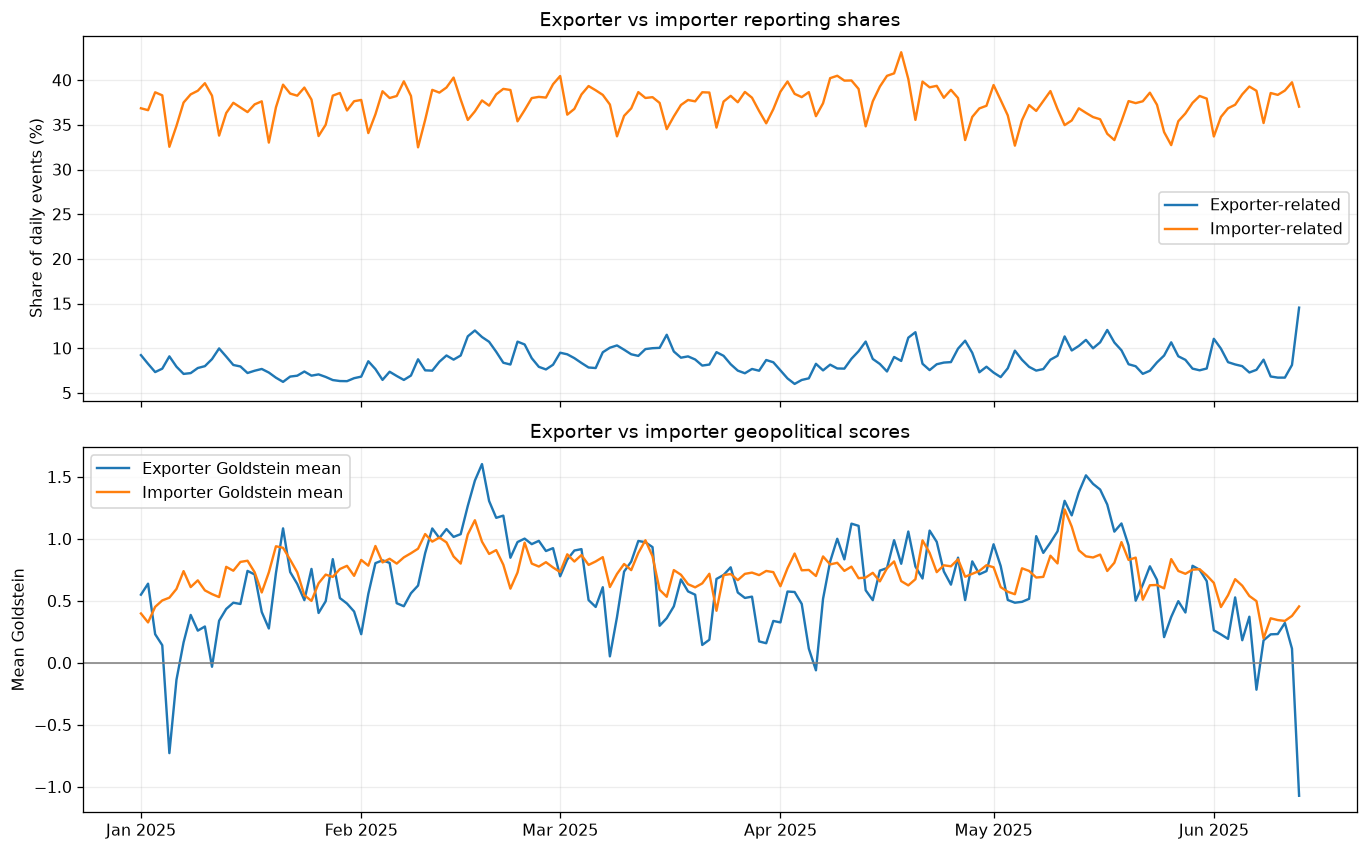

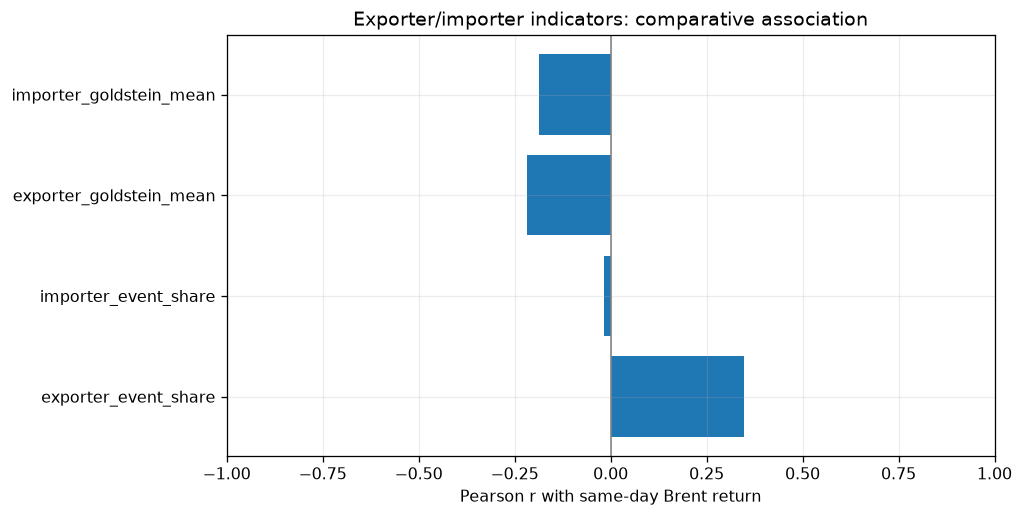

,method,feature,target,n,r,p_value
0,pearson,exporter_event_share,brent_return,112,0.3465,0.0002
1,spearman,exporter_event_share,brent_return,112,0.2267,0.0163
2,pearson,importer_event_share,brent_return,112,-0.0168,0.8604
3,spearman,importer_event_share,brent_return,112,0.0031,0.9743
4,pearson,exporter_goldstein_mean,brent_return,112,-0.2183,0.0207
5,spearman,exporter_goldstein_mean,brent_return,112,-0.1123,0.2384
6,pearson,importer_goldstein_mean,brent_return,112,-0.1864,0.0491
7,spearman,importer_goldstein_mean,brent_return,112,-0.1162,0.2225


In [6]:
eda = df.copy()
eda["exporter_event_share"] = eda.exporter_total_events / eda.global_total_events.replace(0, np.nan)
eda["importer_event_share"] = eda.importer_total_events / eda.global_total_events.replace(0, np.nan)
fig, axes = plt.subplots(2, 1, figsize=(12, 7.5), sharex=True)
axes[0].plot(eda.date, eda.exporter_event_share*100, label="Exporter-related")
axes[0].plot(eda.date, eda.importer_event_share*100, label="Importer-related")
axes[0].set_ylabel("Share of daily events (%)")
axes[0].set_title("Exporter vs importer reporting shares"); axes[0].legend()
axes[1].plot(eda.date, eda.exporter_goldstein_mean, label="Exporter Goldstein mean")
axes[1].plot(eda.date, eda.importer_goldstein_mean, label="Importer Goldstein mean")
axes[1].axhline(0, color="gray", linewidth=1)
axes[1].set_ylabel("Mean Goldstein"); axes[1].set_title("Exporter vs importer geopolitical scores"); axes[1].legend()
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
savefig("05_exporter_importer_time_series")
features5 = ["exporter_event_share", "importer_event_share", "exporter_goldstein_mean", "importer_goldstein_mean"]
rows=[]
for col in features5:
    for method in ["pearson", "spearman"]:
        rows.append({"method": method, **corr_summary(col, data=eda, method=method)})
summary5 = pd.DataFrame(rows)
fig, ax=plt.subplots(figsize=(9, 4.6))
pv = summary5[summary5.method=="pearson"]
ax.barh(pv.feature, pv.r)
ax.axvline(0, color="gray", linewidth=1)
ax.set_xlim(-1,1); ax.set_xlabel("Pearson r with same-day Brent return")
ax.set_title("Exporter/importer indicators: comparative association")
savefig("05_exporter_importer_correlation_comparison")
display(summary5.round(4)); summary5.to_csv(OUT_DIR / "05_exporter_importer_correlations.csv", index=False)

**Interpretation prompts:** Which group has a stronger association, if any? Does this change when moving from raw counts to **daily shares**? Are exporter/importer categories truly comparable when country representation and coverage differ?

## 7. Does internal geopolitical activity among oil exporters relate to Brent returns?

**Question:** Does a higher share of *same-country-actor interactions* involving oil exporters coincide with Brent price movements or absolute return volatility?  
**Approach:** use the existing `exporter_internal_event_share`, plot against Brent return and **absolute return**, and compare against importer internal-event share.

**Critical definition:** An internal event is defined when `Actor1CountryCode == Actor2CountryCode` and both codes are present. **It does not mean domestic conflict**. A higher share is not necessarily an increase in geopolitical instability.

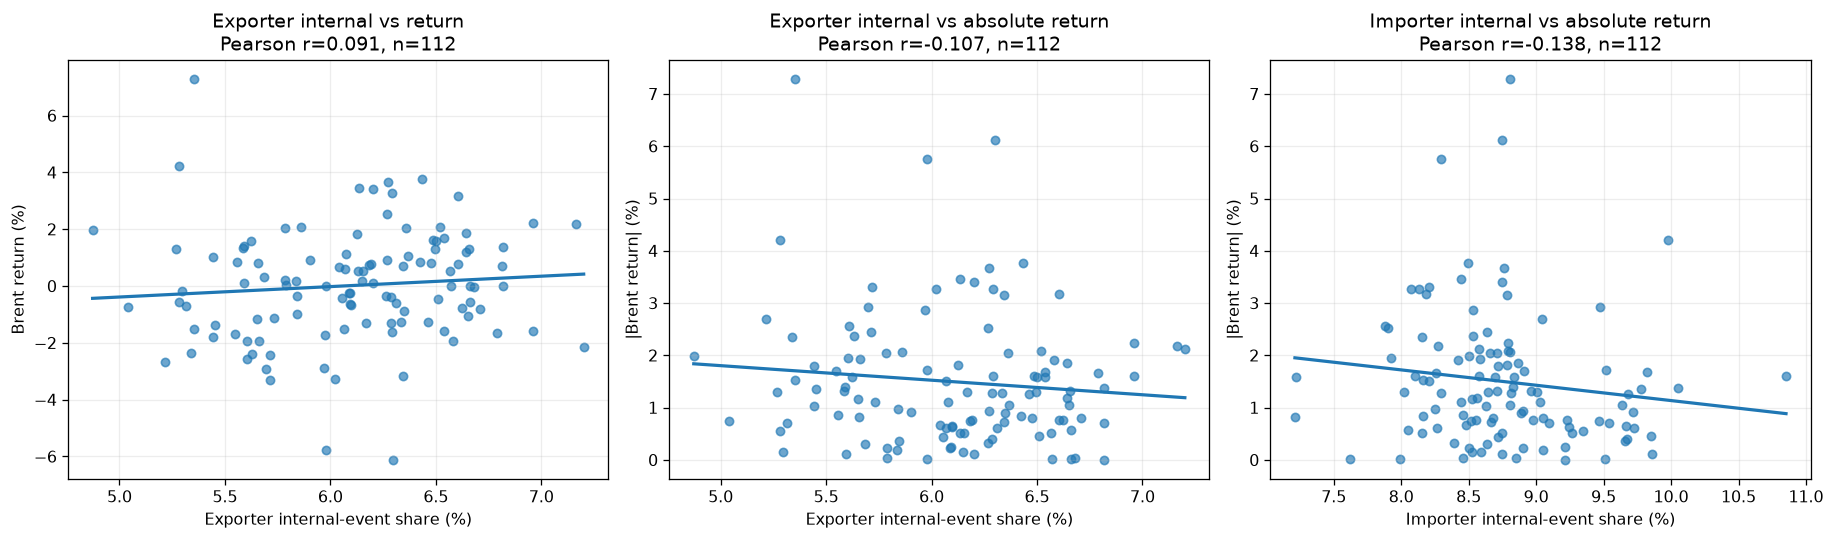

,method,feature,target,n,r,p_value
0,pearson,exporter_internal_event_share,brent_return,112,0.0906,0.3419
1,spearman,exporter_internal_event_share,brent_return,112,0.1612,0.0896
2,pearson,exporter_internal_event_share,absolute_brent_return,112,-0.1067,0.2630
3,spearman,exporter_internal_event_share,absolute_brent_return,112,-0.0767,0.4218
4,pearson,importer_internal_event_share,brent_return,112,0.0102,0.9151
5,spearman,importer_internal_event_share,brent_return,112,0.0317,0.7403
6,pearson,importer_internal_event_share,absolute_brent_return,112,-0.1376,0.1479
7,spearman,importer_internal_event_share,absolute_brent_return,112,-0.2035,0.0314


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
scatter_compare(axes[0], df.exporter_internal_event_share*100, df.brent_return*100,
                "Exporter internal-event share (%)", "Brent return (%)", "Exporter internal vs return")
scatter_compare(axes[1], df.exporter_internal_event_share*100, df.brent_return.abs()*100,
                "Exporter internal-event share (%)", "|Brent return| (%)", "Exporter internal vs absolute return")
scatter_compare(axes[2], df.importer_internal_event_share*100, df.brent_return.abs()*100,
                "Importer internal-event share (%)", "|Brent return| (%)", "Importer internal vs absolute return")
savefig("07_internal_shares_vs_returns")
comp = df.copy()
comp["absolute_brent_return"] = comp.brent_return.abs()
rows=[]
for feature in ["exporter_internal_event_share", "importer_internal_event_share"]:
    for target in ["brent_return", "absolute_brent_return"]:
        for method in ["pearson", "spearman"]:
            rows.append({"method": method, **corr_summary(feature, target=target, data=comp, method=method)})
summary7 = pd.DataFrame(rows)
display(summary7.round(4)); summary7.to_csv(OUT_DIR / "07_internal_activity_correlations.csv", index=False)

**Interpretation prompts:** Is internal activity associated with the **direction** or **magnitude** of price movements? How would you distinguish internal cooperation from internal conflict? What additional features would be needed to study domestic instability specifically?

## Final review: cross-investigation summary and presentation selection

The table below compiles results from the six approved questions. A correlation close to 0 does **not** imply the geopolitical variables are useless: relationships can be nonlinear, delayed, context-dependent, or obscured by reporting noise. Likewise, a nonzero correlation is not causality, and exploratory multiple comparisons can create chance findings.

**Forecasting caution:** These plots align variables by reported **calendar date**, not guaranteed real-time availability. Before forecasting, aggregate news available *before* the relevant Brent price observation and test chronological out-of-sample predictions. With only 113 observed prices, any findings are provisional.

In [8]:
all_corr = pd.concat([
    summary1.assign(investigation="1 Global trend", method="pearson"),
    summary3.assign(investigation="3 Global tone"),
    summary4.assign(investigation="4 Iran/Russia"),
    summary5.assign(investigation="5 Exporter/Importer"),
    summary7.assign(investigation="7 Internal activity")
], ignore_index=True, sort=False)
all_corr["abs_r"] = all_corr.r.abs()
ranked = all_corr[all_corr.method.eq("pearson")].sort_values("abs_r", ascending=False)
print("Exploratory associations (ranked by absolute Pearson r; NOT a feature-selection rule):")
display(ranked[["investigation", "feature", "target", "n", "r", "p_value"]].round(4))
ranked.to_csv(OUT_DIR / "all_investigation_correlations.csv", index=False)
print("\nCharts and statistical summary tables saved in:", OUT_DIR)
print("\nPresentation guidance: choose 3–5 interesting *actual* observations, including at least one surprising or negative finding.")

Exploratory associations (ranked by absolute Pearson r; NOT a feature-selection rule):


,investigation,feature,target,n,r,p_value
12,5 Exporter/Importer,exporter_event_share,brent_return,112,0.3465,0.0002
4,3 Global tone,global_goldstein_mean,brent_return,112,-0.2213,0.0190
16,5 Exporter/Importer,exporter_goldstein_mean,brent_return,112,-0.2183,0.0207
18,5 Exporter/Importer,importer_goldstein_mean,brent_return,112,-0.1864,0.0491
0,1 Global trend,global_total_events,brent_price,113,-0.1573,0.0962
2,3 Global tone,global_tone_mean,brent_return,112,-0.1400,0.1410
26,7 Internal activity,importer_internal_event_share,absolute_brent_return,112,-0.1376,0.1479
1,1 Global trend,global_total_events,brent_return,112,-0.1322,0.1647
10,4 Iran/Russia,russia_goldstein_mean,brent_return,112,-0.1302,0.1712
22,7 Internal activity,exporter_internal_event_share,absolute_brent_return,112,-0.1067,0.2630



Charts and statistical summary tables saved in: C:\Users\kevin\school\Fall 2026\Data Intensive Computing\DIC Semeters Project\Phase 2\Data_wizards\outputs\eda_brent_selected

Presentation guidance: choose 3–5 interesting *actual* observations, including at least one surprising or negative finding.


### Notes to complete after running the notebook

For each chosen finding, prepare four statements:

1. **Question:** What did we investigate?
2. **Technique:** What figure/statistic did we use, and why?
3. **Observation:** What did we actually see? Quote the approximate numbers or correlation, including sample size.
4. **Interpretation and limitation:** What surprised us, and what does the finding tell us about GDELT coverage, Brent pricing, or feature engineering?

Upload the **executed `.ipynb`** back to ChatGPT for interpretation and selection of the strongest 3–5 presentation findings. Do not claim that a statistically significant correlation establishes predictive usefulness.